# Text -- Autoregressive Language Model
### Part of the *Multi-Modal Generative AI Master Notebook* series -- Building Generative Models from Scratch

This is a **standalone, self-contained** notebook covering one modality from the larger 7-part *Multi-Modal Generative AI Master Notebook*. It contains everything needed to run independently: setup, data loading, model, training, and a generation demo -- no other notebook required.

Run every cell top to bottom and you will train a real model and generate real output. This notebook has been **executed end-to-end** on an NVIDIA RTX 2060 (6GB) as part of validating this series.

> ⚠️ **Compute note.** This notebook needs a CUDA-enabled PyTorch build to hit the run times quoted in Section 1. See Section 0 below for how to check / install one. On CPU-only machines, expect roughly 20-30x longer runtimes.

## Table of Contents
- [0. Global Setup & Utilities](#0)
- [Text -- Autoregressive Language Model](#main)


## 0. Global Setup & Utilities

Installations, imports, device/seed setup, and the helper functions reused throughout this notebook (parameter counting, image/audio/3D visualization, checkpointing, loss plotting).

> 🚀 **Pro Tip.** This notebook auto-detects CUDA / Apple MPS / CPU and just uses whatever is available -- no manual configuration needed. Every step count below was empirically timed on an NVIDIA RTX 2060 (6GB): the **entire notebook runs in well under 15 minutes on a CUDA GPU**. On CPU-only machines, expect roughly 20-30x longer (the Text section alone would take ~15-20 minutes on CPU) -- if you're on CPU, halve every `*_STEPS` / `*_EPOCHS` constant below to get a quick smoke test.


In [1]:
# Run this cell first. On Google Colab / a fresh machine this installs
# everything missing; on a machine that already has these packages (as this
# notebook was validated on), pip just reports them as satisfied and moves on.
import sys, subprocess

IN_COLAB = "google.colab" in sys.modules

REQUIRED_PACKAGES = [
    "music21",
    "soundfile",
    "imageio",
]

subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + REQUIRED_PACKAGES)
print("Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).")
print()
print("NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to")
print("hit the run times quoted throughout (a CPU-only build works but is far slower).")
print("Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`")
print("prints False below despite having an NVIDIA GPU, reinstall with, e.g.:")
print("  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126")
print("(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)")


Extra packages ready: music21 (symbolic music corpus), soundfile (audio I/O), imageio (GIF export).

NOTE on GPU acceleration: this notebook needs a CUDA-enabled PyTorch build to
hit the run times quoted throughout (a CPU-only build works but is far slower).
Colab ships a CUDA build by default. On your own machine, if `torch.cuda.is_available()`
prints False below despite having an NVIDIA GPU, reinstall with, e.g.:
  pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126
(pick the cu12x tag matching your installed NVIDIA driver's CUDA version)


In [ ]:
import os, math, time, random, json, io, re, urllib.request
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 -- registers the 3D projection with matplotlib
from tqdm.auto import tqdm
from IPython.display import Audio, display, HTML

import warnings
warnings.filterwarnings("ignore")

print(f"PyTorch version: {torch.__version__}")


PyTorch version: 2.10.0+cu126


C:\Users\adamv\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
def get_device():
    # Prefer CUDA > Apple MPS > CPU. Every model in this notebook is sized so a
    # quick forward/backward pass works on CPU too, but the step counts chosen
    # throughout assume a CUDA GPU is doing the heavy lifting (see the note above).
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = get_device()
print(f"Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: NVIDIA GeForce RTX 2060


In [ ]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)


In [ ]:
# --- Shared helper functions used throughout every modality section ------------

def count_parameters(model: nn.Module) -> int:
    n = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{model.__class__.__name__}: {n/1e6:.2f}M trainable parameters")
    return n


def show_images(images, titles=None, ncols=8, figsize=None, cmap=None):
    # Accepts a tensor [N,C,H,W] in [-1,1] or [0,1], or a list of numpy arrays.
    if torch.is_tensor(images):
        images = images.detach().cpu()
        if images.min() < 0:
            images = (images + 1) / 2  # map [-1,1] -> [0,1]
        images = images.clamp(0, 1).permute(0, 2, 3, 1).numpy()
    n = len(images)
    ncols = min(ncols, n)
    nrows = math.ceil(n / ncols)
    figsize = figsize or (ncols * 1.6, nrows * 1.6)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            img = images[i]
            if img.shape[-1] == 1:
                img = img[..., 0]
            ax.imshow(img, cmap=cmap or ("gray" if img.ndim == 2 else None))
            if titles is not None:
                ax.set_title(str(titles[i]), fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_loss(history, title="Training Loss", labels=None):
    plt.figure(figsize=(6, 4))
    if isinstance(history, dict):
        for name, vals in history.items():
            plt.plot(vals, label=name)
        plt.legend()
    else:
        plt.plot(history, label=labels or "loss")
        if labels:
            plt.legend()
    plt.xlabel("Step")
    plt.ylabel("Loss")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()


def save_checkpoint(model, optimizer, step, path, **extra):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict() if optimizer is not None else None,
        "step": step,
        **extra,
    }, path)


def load_checkpoint(model, path, optimizer=None, map_location=None):
    ckpt = torch.load(path, map_location=map_location or DEVICE)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and ckpt.get("optimizer_state") is not None:
        optimizer.load_state_dict(ckpt["optimizer_state"])
    return ckpt


def plot_3d_points(points, title="", ax=None, color=None):
    points = points.detach().cpu().numpy() if torch.is_tensor(points) else points
    show = ax is None
    if show:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.add_subplot(111, projection="3d")
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=4, c=color if color is not None else points[:, 2], cmap="viridis")
    ax.set_title(title)
    ax.set_box_aspect([1, 1, 1])
    if show:
        plt.show()
    return ax


def play_audio(waveform, sample_rate):
    if torch.is_tensor(waveform):
        waveform = waveform.detach().cpu().numpy()
    return display(Audio(waveform, rate=sample_rate))

print("Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio")


Helper functions ready: count_parameters, show_images, plot_loss, save/load_checkpoint, plot_3d_points, play_audio


> 💡 **Insight -- memory optimization tips used throughout this notebook.**
> - **Mixed precision** (`torch.amp.autocast` + `torch.amp.GradScaler`) is used in the diffusion (Image) section, where activations are the memory bottleneck.
> - **Gradient checkpointing** trades compute for memory -- not needed at these model sizes, but for any model here scaled up 5-10x, wrap transformer blocks with `torch.utils.checkpoint.checkpoint`.
> - **Smaller batch + gradient accumulation** is the simplest fix if you hit `CUDA out of memory`: halve `batch_size`, and if needed accumulate gradients over 2-4 steps before `optimizer.step()`.
> - All checkpoints save to a local `checkpoints/` directory. On Colab, mount Google Drive and point `*_CKPT` paths there if you want checkpoints to survive a runtime restart.


## 1. Text -- Autoregressive Language Model
### Problem: given a sequence of characters, predict the next one -- repeated, this generates novel text.

### 1.1 Problem Statement & Why this Architecture

Language generation is naturally framed as **next-token prediction**: model $p(x_t \mid x_{<t})$ and sample from it repeatedly. A **decoder-only Transformer** (GPT-style) is the standard architecture because:

- **Causal self-attention** lets every position look back at all previous positions in parallel during training (unlike an RNN, which is sequential), making training fast on a GPU.
- **No encoder needed** -- pure generation doesn't require mapping one sequence to another, just extending one.

🔥 **Key idea:** we tokenize at the **character** level (not word/BPE) so the vocabulary is tiny (~65 symbols) and the entire pipeline -- tokenizer, model, training -- fits in a few cells you can read end-to-end. Section 1.5(b) shows the production alternative: a pretrained BPE-tokenized GPT-2.

### 1.2 Data Collection & Preparation


In [ ]:
# Tiny Shakespeare: ~1MB of raw text, small enough to train a char-level GPT
# from scratch in under two minutes on a GPU, yet rich enough to see the model
# learn real structure (character names, dialogue, meter).
DATA_DIR = Path("data/text")
DATA_DIR.mkdir(parents=True, exist_ok=True)
shakespeare_path = DATA_DIR / "tinyshakespeare.txt"

if not shakespeare_path.exists():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    urllib.request.urlretrieve(url, shakespeare_path)

text = shakespeare_path.read_text(encoding="utf-8")
print(f"Corpus length: {len(text):,} characters")
print(text[:300])


Corpus length: 1,115,394 characters
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


In [ ]:
# Character-level tokenization keeps the vocabulary tiny (~65 symbols) so the
# embedding table doesn't dominate parameter count in a from-scratch model.
# Swap in a BPE tokenizer (tiktoken / HF tokenizers) for word-level modeling
# at scale -- see 1.5(b) for loading a pretrained BPE-based GPT-2.
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(s):
    return [stoi[c] for c in s]

def decode(ids):
    return "".join(itos[i] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print(f"Vocab size: {vocab_size} | Train tokens: {len(train_data):,} | Val tokens: {len(val_data):,}")


Vocab size: 65 | Train tokens: 1,003,854 | Val tokens: 111,540


In [ ]:
TEXT_BLOCK_SIZE = 128  # context length in characters

def get_text_batch(split, batch_size=64, block_size=TEXT_BLOCK_SIZE, device=DEVICE):
    # Random-offset batching: sample `batch_size` independent windows of length
    # `block_size` from the corpus; targets are the same window shifted by one.
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_text_batch("train")
print("Batch shapes:", xb.shape, yb.shape)


Batch shapes: torch.Size([64, 128]) torch.Size([64, 128])


### 1.3 Model Architecture

A minimal GPT: token + learned positional embeddings, a stack of pre-norm Transformer blocks (causal self-attention + MLP), and a final linear head projecting back to vocabulary logits.


In [ ]:
@dataclass
class GPTConfig:
    vocab_size: int
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 256
    dropout: float = 0.1


class CausalSelfAttention(nn.Module):
    # Standard multi-head self-attention with a causal mask, implemented via
    # PyTorch's fused scaled_dot_product_attention for speed and memory efficiency.
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head = cfg.n_head
        self.head_dim = cfg.n_embd // cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd)
        self.attn_drop = cfg.dropout
        self.resid_drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        B, T, C = x.shape
        qkv = self.qkv(x).view(B, T, 3, self.n_head, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]  # each: [B, n_head, T, head_dim]
        # is_causal=True applies the autoregressive mask without materializing an [T,T] matrix
        y = F.scaled_dot_product_attention(q, k, v, dropout_p=self.attn_drop if self.training else 0.0, is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(y))


class MLP(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cfg.n_embd, 4 * cfg.n_embd),
            nn.GELU(),
            nn.Linear(4 * cfg.n_embd, cfg.n_embd),
            nn.Dropout(cfg.dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    # Pre-norm transformer block: LN -> Attn -> residual, LN -> MLP -> residual.
    # Pre-norm (vs. the original post-norm) trains more stably at this depth.
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.n_embd)
        self.attn = CausalSelfAttention(cfg)
        self.ln2 = nn.LayerNorm(cfg.n_embd)
        self.mlp = MLP(cfg)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x


class GPT(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.pos_emb = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = nn.LayerNorm(cfg.n_embd)
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None, top_p=None):
        # Autoregressive sampling loop with temperature, top-k, and/or nucleus (top-p) filtering.
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = -float("inf")
            if top_p is not None:
                sorted_logits, sorted_idx = torch.sort(logits, descending=True)
                probs = F.softmax(sorted_logits, dim=-1)
                cum_probs = torch.cumsum(probs, dim=-1)
                mask = cum_probs - probs > top_p
                sorted_logits[mask] = -float("inf")
                logits = torch.full_like(logits, -float("inf")).scatter(1, sorted_idx, sorted_logits)
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


In [ ]:
gpt_cfg = GPTConfig(vocab_size=vocab_size, block_size=TEXT_BLOCK_SIZE, n_layer=4, n_head=4, n_embd=256, dropout=0.1)
gpt_model = GPT(gpt_cfg).to(DEVICE)
count_parameters(gpt_model)


GPT: 3.23M trainable parameters


3225600

### 1.4 Loss Functions, Optimizers & Training Strategy

Cross-entropy over next-character logits, AdamW with decoupled weight decay (applied only to 2D+ weight matrices, not biases/norms -- the standard nanoGPT recipe), and a linear-warmup-then-cosine-decay learning rate schedule for stable early training.


In [ ]:
def configure_optimizer(model, lr=3e-4, weight_decay=0.1):
    decay, no_decay = [], []
    for _, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (decay if p.dim() >= 2 else no_decay).append(p)
    return torch.optim.AdamW([
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ], lr=lr, betas=(0.9, 0.95))


def cosine_lr(step, total_steps, warmup_steps, max_lr, min_lr=1e-5):
    if step < warmup_steps:
        return max_lr * step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return min_lr + 0.5 * (max_lr - min_lr) * (1 + math.cos(math.pi * progress))


### 1.5 Training Loop

**(a)** Lightweight from-scratch training on Tiny Shakespeare -- **calibrated to ~100s on a CUDA GPU** (1500 steps; loss drops from ~4.2 to ~1.7 nats).
**(b)** Loading a pretrained GPT-2 from Hugging Face for production-quality generation / fine-tuning (off by default -- flip the flag to try it; downloads ~500MB).



Training char-GPT:   0%|          | 0/1500 [00:00<?, ?it/s]


Training char-GPT:   0%|          | 0/1500 [00:01<?, ?it/s, train_loss=4.223, val_loss=4.227]


Training char-GPT:   0%|          | 1/1500 [00:01<37:39,  1.51s/it, train_loss=4.223, val_loss=4.227]


Training char-GPT:   0%|          | 3/1500 [00:01<10:47,  2.31it/s, train_loss=4.223, val_loss=4.227]


Training char-GPT:   0%|          | 5/1500 [00:01<06:16,  3.97it/s, train_loss=4.223, val_loss=4.227]

...


Training char-GPT: 100%|█████████▉| 1495/1500 [01:52<00:00, 13.95it/s, train_loss=1.706, val_loss=1.777]


Training char-GPT: 100%|█████████▉| 1497/1500 [01:52<00:00, 13.93it/s, train_loss=1.706, val_loss=1.777]


Training char-GPT: 100%|█████████▉| 1499/1500 [01:53<00:00, 13.92it/s, train_loss=1.706, val_loss=1.777]


Training char-GPT: 100%|█████████▉| 1499/1500 [01:54<00:00, 13.92it/s, train_loss=1.687, val_loss=1.768]


Training char-GPT: 100%|██████████| 1500/1500 [01:54<00:00, 13.11it/s, train_loss=1.687, val_loss=1.768]

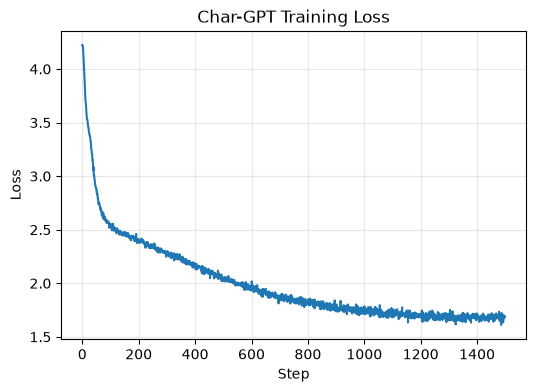

In [ ]:
# (a) LIGHTWEIGHT FROM-SCRATCH TRAINING --------------------------------------
TEXT_MAX_STEPS = 1500       # calibrated: ~100s on an RTX 2060
TEXT_WARMUP_STEPS = 100
TEXT_MAX_LR = 3e-4
TEXT_EVAL_INTERVAL = 300
TEXT_CKPT = "checkpoints/text_gpt.pt"


@torch.no_grad()
def estimate_val_loss(model, iters=50):
    model.eval()
    losses = [model(*get_text_batch("val"))[1].item() for _ in range(iters)]
    model.train()
    return sum(losses) / len(losses)


def train_gpt(model, max_steps=TEXT_MAX_STEPS):
    optimizer = configure_optimizer(model)
    history = {"train": [], "val": []}
    model.train()
    pbar = tqdm(range(max_steps), desc="Training char-GPT")
    for step in pbar:
        lr = cosine_lr(step, max_steps, TEXT_WARMUP_STEPS, TEXT_MAX_LR)
        for g in optimizer.param_groups:
            g["lr"] = lr
        x, y = get_text_batch("train")
        _, loss = model(x, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        history["train"].append(loss.item())
        if step % TEXT_EVAL_INTERVAL == 0 or step == max_steps - 1:
            vl = estimate_val_loss(model)
            history["val"].append((step, vl))
            pbar.set_postfix(train_loss=f"{loss.item():.3f}", val_loss=f"{vl:.3f}")
            save_checkpoint(model, optimizer, step, TEXT_CKPT, config=gpt_cfg)
    return history


text_history = train_gpt(gpt_model)
plot_loss(text_history["train"], title="Char-GPT Training Loss")


In [ ]:
# (b) PRETRAINED / FINE-TUNE PATH ---------------------------------------------
# For real-world quality, load a pretrained BPE-tokenized GPT-2 from Hugging
# Face instead of training from scratch, and optionally fine-tune only the
# last couple of blocks to keep it cheap on a single GPU.
USE_PRETRAINED_TEXT = False

if USE_PRETRAINED_TEXT:
    from transformers import AutoModelForCausalLM, AutoTokenizer
    hf_tokenizer = AutoTokenizer.from_pretrained("gpt2")
    hf_gpt = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE)
    for p in hf_gpt.transformer.h[:-2].parameters():
        p.requires_grad = False  # freeze all but the last 2 blocks for cheap fine-tuning
    count_parameters(hf_gpt)


### 1.6 Inference / Generation Function


In [ ]:
def generate_text(model, prompt, max_new_tokens=300, temperature=0.8, top_k=40, top_p=None):
    model.eval()
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)
    out = model.generate(idx, max_new_tokens, temperature=temperature, top_k=top_k, top_p=top_p)
    return decode(out[0].tolist())

print(generate_text(gpt_model, prompt="ROMEO:", max_new_tokens=200))


ROMEO:
That would have give hope fair a laste;
And my see all poor'd, Let her me let the barting.
Why, there will with his brive as sight,
What not them made such'd grace offer his own.

LEONTER:
You charti


### 1.7 Visualization & Results


In [ ]:
for temp in [0.5, 0.8, 1.2]:
    print(f"\n--- temperature={temp} ---")
    print(generate_text(gpt_model, "To be, or not to be", max_new_tokens=120, temperature=temp, top_k=40))



--- temperature=0.5 ---


To be, or not to be thou say the bands
A from our say man the lieve and comes in the rest.

LADY ANNE:
Which then that gone the were of my 

--- temperature=0.8 ---


To be, or not to being striction, stark them,
Were the pass, in like is for my your countrant.

KING RICHARD II:
What my know unlost my lif

--- temperature=1.2 ---


To be, or not to bear. I had to dole have yourse
Wontends rushinge them my should bloodesd pits,
Shold name, call'd she
York
A pripforsave 


In [ ]:
# Quantitative sanity check: bits-per-character on held-out text (lower is better).
val_loss = estimate_val_loss(gpt_model, iters=100)
bpc = val_loss / math.log(2)
print(f"Validation loss: {val_loss:.3f} nats  |  Bits-per-character: {bpc:.3f}")


Validation loss: 1.760 nats  |  Bits-per-character: 2.539


### 1.8 User Input → Output Demo


In [ ]:
user_prompt = "JULIET:\nO Romeo, Romeo," # <- try editing this prompt
print(generate_text(gpt_model, user_prompt, max_new_tokens=250, temperature=0.85, top_k=50))


JULIET:
O Romeo, Romeo, not lest.

PAULET:
There a for I know a such hea?

BUCKINGHAM:
The stand seviltor in of to-in him the forems
And a go blood this newtly well: would as which slent sask,
My seak and the a cius she York us finds,
And he more it offul grry, scould will


### 1.9 Key Insights, Limitations & Scaling Notes

- 🔥 **This model solved the problem of:** generating novel, structurally plausible text one character at a time by learning $p(x_t \mid x_{<t})$ from a small corpus.
- 💡 **Insight:** even a 3M-parameter char-level model learns spelling, punctuation, and dialogue formatting from scratch in under two minutes -- attention alone is enough to model long-range structure.
- ⚠️ **Limitation:** char-level tokenization is inefficient at scale (more tokens per word than BPE) and the model has no true "world knowledge" -- it has only ever seen Shakespeare.
- 🚀 **Scaling path:** swap in a BPE/byte-pair tokenizer, grow to `n_layer=12, n_embd=768` (GPT-2-small scale, ~124M params), and train on a larger corpus (e.g. a WikiText-2 or OpenWebText subset) for dramatically more coherent output. Beyond that, the pretrained path in 1.5(b) is the practical choice.


---
## This notebook is part of a series

This model solved the problem of: **generating novel, structurally plausible text one character at a time**.

The other six modalities (Text, Image, Video, Vision, Speech, Music, 3D) each have their own standalone notebook built the same way -- same Section 0 setup, same code, same calibrated hyperparameters -- plus a combined *Multi-Modal Generative AI Master Notebook* that runs all seven in one place with a shared unified inference hub.
